<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Extracted lines still need an input audit

**Which extracted values are eligible for an aggregate, and which inputs disappeared
before extraction?** We will use VGI X12 to inspect synthetic purchase-order envelope
checks, extract positional line fields, retain invalid numeric values, and calculate
a clearly scoped selected-line subtotal.

Six authored files and one missing-input record contain no private business or health
data. These are variations of one test order, not seven independent purchases. The
worker checks structural counts and control-number agreement; it does not establish
full EDI business-rule compliance. Raw codes remain uninterpreted.

## Choose whether to preview incomplete envelopes

`ALLOW_INCOMPLETE=False` requires all six envelope checks to be true. The experiment
sets it to `True`, allowing unknown checks only when none is false. A known failure
always remains excluded. This is a reporting preview, not acceptance of an interchange.
Numeric quality is checked separately in both modes. Restart and run all after changing it.

In [1]:
ALLOW_INCOMPLETE = False

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from decimal import Decimal
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from notebook_support import finish, prose, theme

if type(ALLOW_INCOMPLETE) is not bool:
    raise ValueError("ALLOW_INCOMPLETE must be True or False.")
audit = summary = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-x12/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-x12/notebooks/pyproject.toml.

## Attach the release and inventory the inputs

The literal native release location requires no Rust build. File reads below are
local to the notebook directory. The input inventory is created before any worker
table function runs, so files yielding zero transaction or line rows remain visible.
A missing input is represented by NULL in the inventory, not a nonexistent filesystem
path passed to the worker (which would correctly raise a file error).

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'x12' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-x12@v0.4.0');
CREATE TABLE inputs AS SELECT filename AS source_path,
 regexp_extract(filename,'([^/]+)\.edi$',1) AS document_id,content AS edi_text
FROM read_text('fixtures/*.edi')
UNION ALL SELECT NULL,'missing',NULL;
SELECT document_id,length(edi_text) AS supplied_characters FROM inputs ORDER BY document_id;

,document_id,supplied_characters
0,bad-count,364
1,bad-quantity,369
2,complete,363
3,incomplete,338
4,missing,<NA>
5,no-se,217
6,no-transactions,183


## Audit structural checks before extracting values

The complete fixture has two PO1 lines. Variants alter only one aspect: a wrong SE
count, a nonnumeric quantity, missing GE/IEA trailers, a missing SE and outer trailers,
or an interchange with no ST transaction. Envelope keys are reused across files on
purpose. Joins must include the source path as well as the envelope identifiers.

A false flag means a check failed. NULL means the matching trailer is unavailable.
All true means only that these structural checks passed. It does not validate raw
quantities or prove compliance with a transaction implementation guide.

In [4]:
%%sql
CREATE TABLE envelope_raw AS SELECT * FROM x12.main.envelope('fixtures/*.edi');
CREATE TABLE envelopes AS SELECT *,CASE
 WHEN se_count_ok IS FALSE OR ge_count_ok IS FALSE OR iea_count_ok IS FALSE
   OR se_ctrl_match IS FALSE OR ge_ctrl_match IS FALSE OR iea_ctrl_match IS FALSE THEN 'Failed'
 WHEN se_count_ok AND ge_count_ok AND iea_count_ok AND se_ctrl_match AND ge_ctrl_match AND iea_ctrl_match THEN 'Checks passed'
 ELSE 'Incomplete' END AS envelope_state
FROM envelope_raw;
CREATE TABLE input_audit AS SELECT i.document_id,i.source_path,
 CASE WHEN i.edi_text IS NULL THEN 'Missing input'
 WHEN e.transaction_ctrl IS NULL THEN 'No transaction emitted' ELSE e.envelope_state END AS input_state,
 e.interchange_ctrl,e.group_ctrl,e.transaction_ctrl,e.transaction_type,
 e.se_count_ok,e.ge_count_ok,e.iea_count_ok,e.se_ctrl_match,e.ge_ctrl_match,e.iea_ctrl_match
FROM inputs i LEFT JOIN envelopes e ON i.source_path=e.source_path;
SELECT * EXCLUDE(source_path) FROM input_audit ORDER BY document_id;

,document_id,input_state,interchange_ctrl,group_ctrl,transaction_ctrl,transaction_type,se_count_ok,ge_count_ok,iea_count_ok,se_ctrl_match,ge_ctrl_match,iea_ctrl_match
0,bad-count,Failed,000000400,1,0001,850,False,True,True,True,True,True
1,bad-quantity,Checks passed,000000400,1,0001,850,True,True,True,True,True,True
2,complete,Checks passed,000000400,1,0001,850,True,True,True,True,True,True
3,incomplete,Incomplete,000000400,1,0001,850,True,<NA>,<NA>,True,<NA>,<NA>
4,missing,Missing input,None,None,None,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5,no-se,Incomplete,000000400,1,0001,850,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
6,no-transactions,No transaction emitted,None,None,None,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [5]:
%%sql audit <<
SELECT document_id,input_state,se_count_ok,ge_count_ok,iea_count_ok,
 se_ctrl_match,ge_ctrl_match,iea_ctrl_match FROM input_audit ORDER BY document_id;

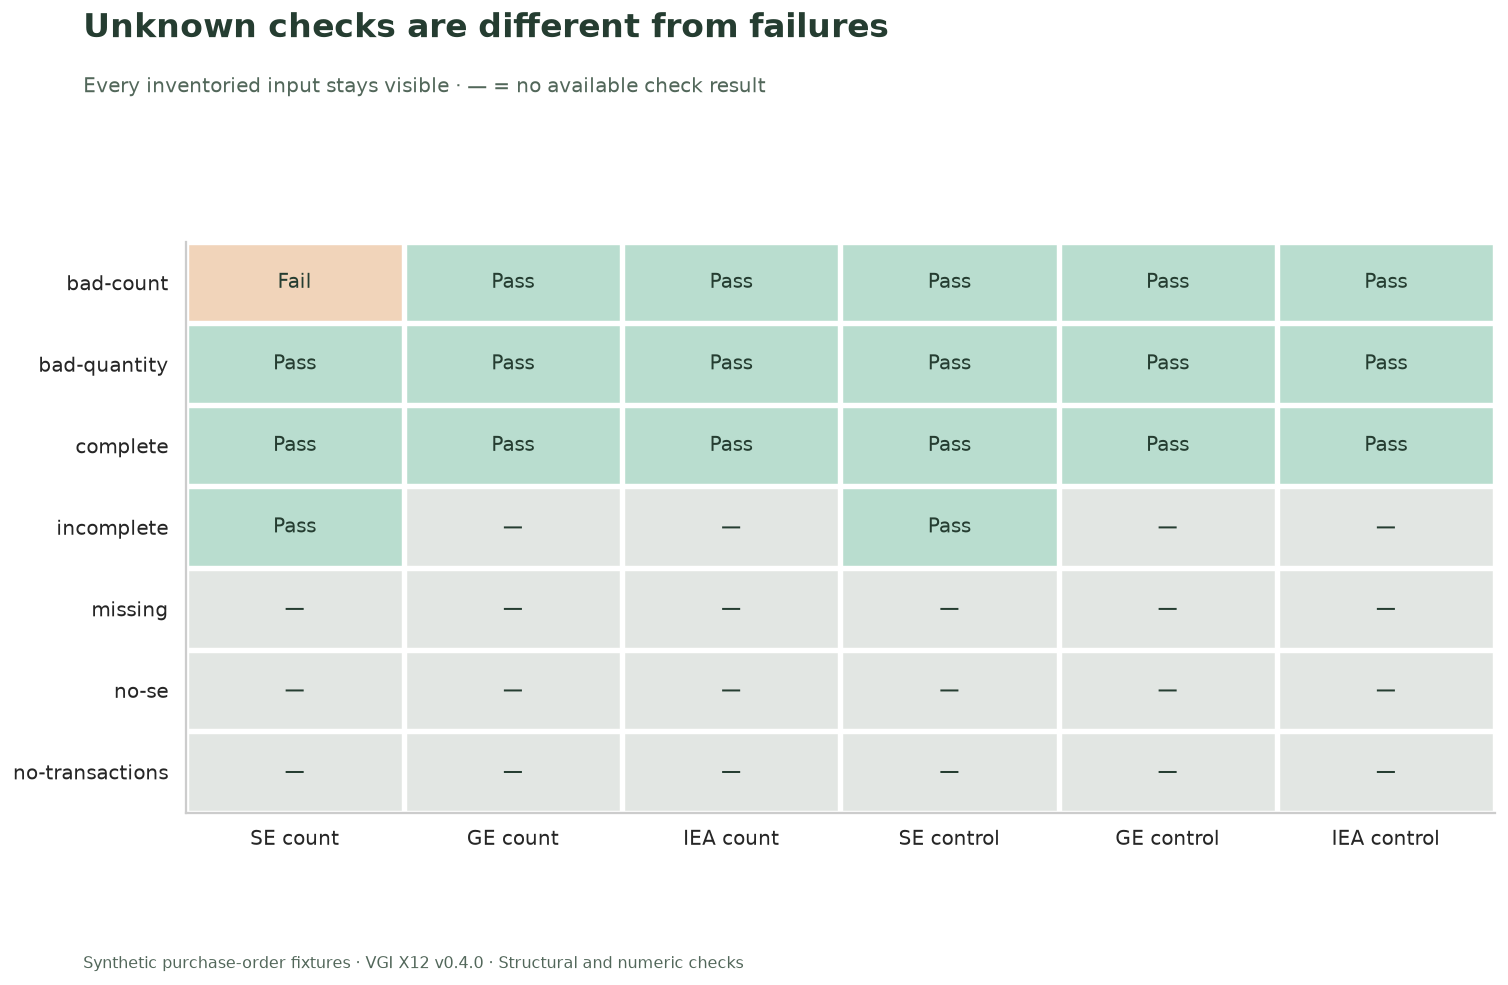

The audit retains **7 input records**. The bad-quantity file passes the envelope checks despite its nonnumeric field. Missing trailers, no emitted transaction and missing input remain distinct in the table above.

In [6]:
columns = [
    "se_count_ok",
    "ge_count_ok",
    "iea_count_ok",
    "se_ctrl_match",
    "ge_ctrl_match",
    "iea_ctrl_match",
]
values = np.array(
    [
        [0 if pd.isna(v) else 2 if bool(v) else 1 for v in row]
        for row in audit[columns].itertuples(index=False, name=None)
    ]
)
fig, ax = plt.subplots(figsize=(12, 7.7))
ax.imshow(
    values, cmap=ListedColormap(["#e2e6e3", "#f1d4ba", "#b9ddcf"]), vmin=0, vmax=2, aspect="auto"
)
ax.set_xticks(
    range(6), ["SE count", "GE count", "IEA count", "SE control", "GE control", "IEA control"]
)
ax.set_yticks(range(len(audit)), audit.document_id)
ax.set_xticks(np.arange(-0.5, 6, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(audit), 1), minor=True)
ax.grid(False)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
for y, row in enumerate(values):
    for x, v in enumerate(row):
        ax.text(
            x, y, ["—", "Fail", "Pass"][v], ha="center", va="center", fontsize=11, color="#253d31"
        )
finish(
    fig,
    "Unknown checks are different from failures",
    "Every inventoried input stays visible · — = no available check result",
    "01_envelope_evidence.png",
    bottom=0.12,
)
prose(
    f"The audit retains **{len(audit)} input records**. The bad-quantity file passes the envelope checks despite its nonnumeric field. Missing trailers, no emitted transaction and missing input remain distinct in the table above."
)

## Extract raw positional fields and preserve join scope

`read_850` emits one row per extracted PO1 line, carrying envelope keys down. Keep
those keys and `source_path` in the join. A control number by itself would cross-match
these deliberately repeated test orders.

The pinned release emits lines from the file whose SE exists but GE/IEA are missing.
It emits an envelope row but no shaped lines when SE is also missing. A no-transaction
file yields neither. The inventory therefore supplies a necessary denominator that
the shaped table cannot reconstruct by itself.

In [7]:
%%sql
CREATE TABLE raw_lines AS SELECT * FROM x12.main.read_850('fixtures/*.edi');
CREATE TABLE scoped_lines AS SELECT p.*,e.envelope_state,i.document_id,
 try_cast(nullif(trim(p.po1_quantity),'') AS DECIMAL(18,4)) AS quantity,
 try_cast(nullif(trim(p.po1_unit_price),'') AS DECIMAL(18,4)) AS unit_price
FROM raw_lines p JOIN envelopes e
 ON p.source_path=e.source_path AND p.interchange_ctrl=e.interchange_ctrl
 AND p.group_ctrl=e.group_ctrl AND p.transaction_ctrl=e.transaction_ctrl
 AND p.transaction_type=e.transaction_type
JOIN inputs i ON p.source_path=i.source_path;
SELECT document_id,interchange_ctrl,group_ctrl,transaction_ctrl,po1_line_number,
 po1_quantity,po1_uom,po1_unit_price,quantity,unit_price,envelope_state
FROM scoped_lines ORDER BY document_id,po1_line_number;

,document_id,interchange_ctrl,group_ctrl,transaction_ctrl,po1_line_number,po1_quantity,po1_uom,po1_unit_price,quantity,unit_price,envelope_state
0,bad-count,000000400,1,0001,1,10,EA,4.50,10.0,4.50,Failed
1,bad-count,000000400,1,0001,2,5,EA,9.99,5.0,9.99,Failed
2,bad-quantity,000000400,1,0001,1,10,EA,4.50,10.0,4.50,Checks passed
3,bad-quantity,000000400,1,0001,2,unknown,EA,9.99,NaN,9.99,Checks passed
4,complete,000000400,1,0001,1,10,EA,4.50,10.0,4.50,Checks passed
5,complete,000000400,1,0001,2,5,EA,9.99,5.0,9.99,Checks passed
6,incomplete,000000400,1,0001,1,10,EA,4.50,10.0,4.50,Incomplete
7,incomplete,000000400,1,0001,2,5,EA,9.99,5.0,9.99,Incomplete


## Define numeric eligibility independently

The fixture declares a common fictional price scale. For this demonstration, multiply
the raw quantity and unit-price fields only when both parse as nonnegative decimal
values. The raw unit code is retained; no code-set meaning, currency conversion,
charge/tax calculation or business acceptance is inferred.

A malformed quantity stays NULL, not zero. Its line remains in the audit and has no
known line amount. Envelope eligibility controls whether a valid numeric line enters
the selected subtotal; it does not alter the original flags or repair the source.

In [8]:
%%sql
CREATE TABLE line_quality AS SELECT *,
 coalesce(quantity>=0 AND unit_price>=0,false) AS numeric_eligible,
 envelope_state='Checks passed' OR ({{ ALLOW_INCOMPLETE }} AND envelope_state='Incomplete') AS envelope_eligible
FROM scoped_lines;
CREATE TABLE line_audit AS SELECT *,
 CASE WHEN numeric_eligible THEN quantity*unit_price END AS known_line_amount,
 numeric_eligible AND envelope_eligible AS selected
FROM line_quality;
SELECT document_id,po1_line_number,po1_quantity,po1_unit_price,po1_uom,
 known_line_amount,numeric_eligible,envelope_eligible,selected
FROM line_audit ORDER BY document_id,po1_line_number;

,document_id,po1_line_number,po1_quantity,po1_unit_price,po1_uom,known_line_amount,numeric_eligible,envelope_eligible,selected
0,bad-count,1,10,4.50,EA,45.00,True,False,False
1,bad-count,2,5,9.99,EA,49.95,True,False,False
2,bad-quantity,1,10,4.50,EA,45.00,True,True,True
3,bad-quantity,2,unknown,9.99,EA,NaN,False,True,False
4,complete,1,10,4.50,EA,45.00,True,True,True
5,complete,2,5,9.99,EA,49.95,True,True,True
6,incomplete,1,10,4.50,EA,45.00,True,False,False
7,incomplete,2,5,9.99,EA,49.95,True,False,False


## Reconcile selected amounts to every input

Summarize from the input inventory with a left join. The selected subtotal is zero
when no lines are selected, but that zero is not an order value. The table also shows
extracted line count, numeric failures, withheld numeric lines and the subtotal of
all known numeric lines. No known lines produces NULL for that last subtotal.

The files are alternative test cases, so adding their selected amounts is an audit
reconciliation only. It is not total procurement spend or an estimate for omitted lines.

In [9]:
%%sql summary <<
SELECT a.document_id,a.input_state,count(l.po1_line_number) AS extracted_lines,
 count(*) FILTER(WHERE l.numeric_eligible=false) AS invalid_numeric_lines,
 count(*) FILTER(WHERE l.numeric_eligible AND NOT l.envelope_eligible) AS withheld_numeric_lines,
 count(*) FILTER(WHERE l.selected) AS selected_lines,
 sum(l.known_line_amount) AS all_known_numeric_subtotal,
 coalesce(sum(l.known_line_amount) FILTER(WHERE l.selected),0) AS selected_subtotal
FROM input_audit a LEFT JOIN line_audit l ON a.source_path=l.source_path
 AND a.interchange_ctrl=l.interchange_ctrl AND a.group_ctrl=l.group_ctrl
 AND a.transaction_ctrl=l.transaction_ctrl AND a.transaction_type=l.transaction_type
GROUP BY a.document_id,a.input_state ORDER BY a.document_id;

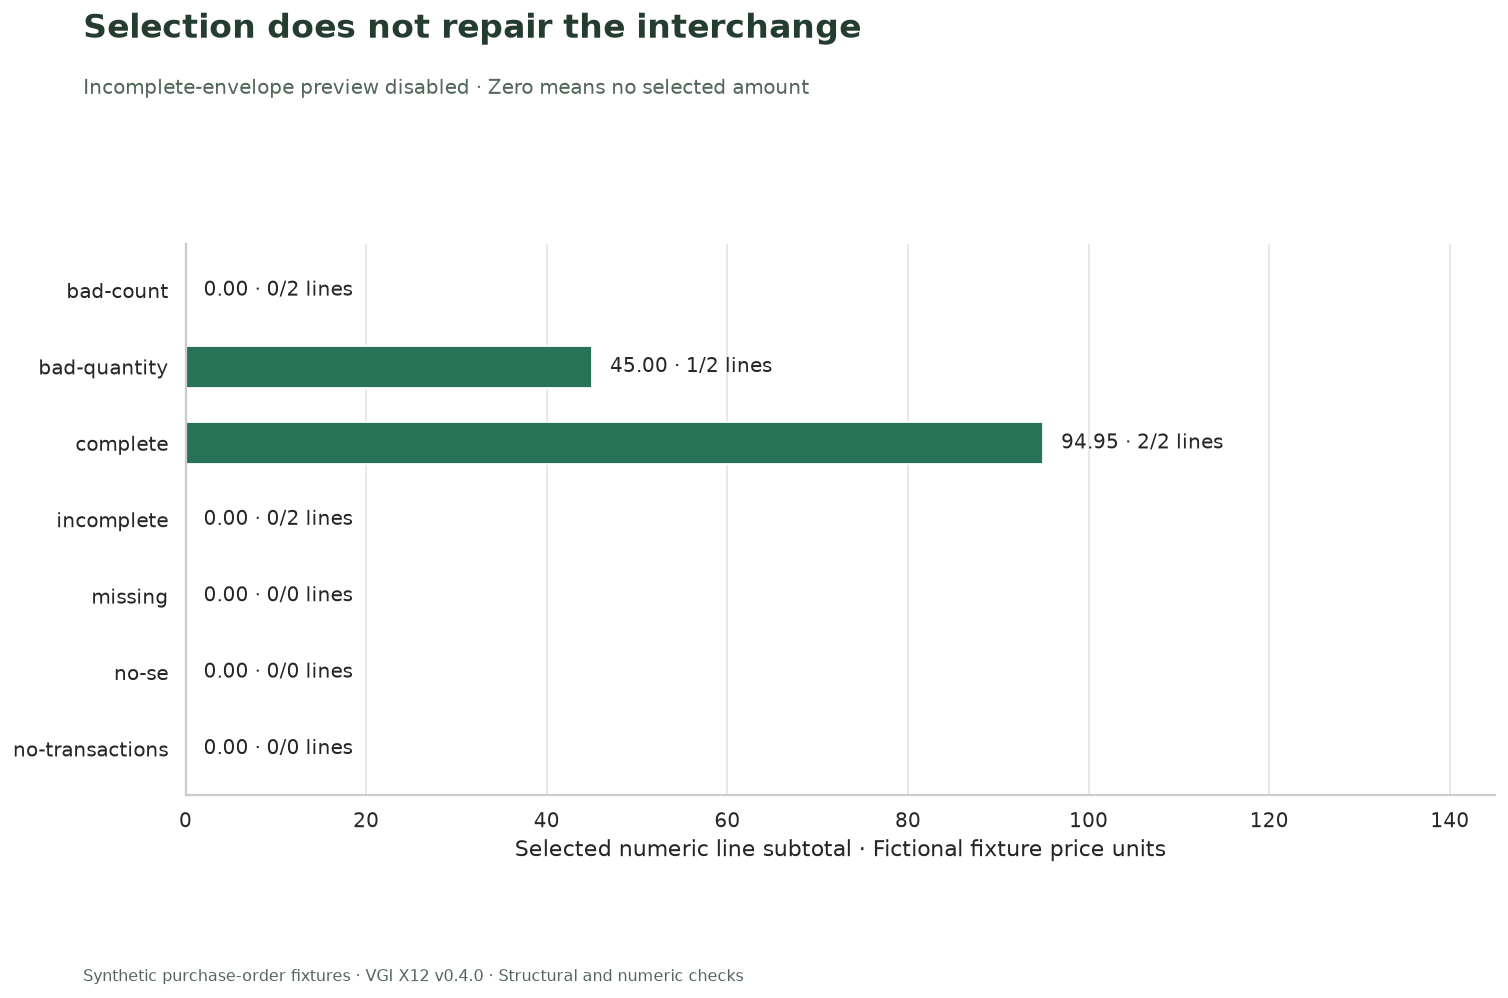

**3 of 8 extracted lines** contribute **139.95 fixture price units** to the selected audit sum. **1 numeric failure(s)** remain explicit. The missing-SE file has no shaped rows, even when incomplete-envelope preview is enabled; its envelope row remains visible.

,document_id,input_state,extracted_lines,invalid_numeric_lines,withheld_numeric_lines,selected_lines,all_known_numeric_subtotal,selected_subtotal
0,bad-count,Failed,2,0,2,0,94.95,0.00
1,bad-quantity,Checks passed,2,1,0,1,45.00,45.00
2,complete,Checks passed,2,0,0,2,94.95,94.95
3,incomplete,Incomplete,2,0,2,0,94.95,0.00
4,missing,Missing input,0,0,0,0,NaN,0.00
5,no-se,Incomplete,0,0,0,0,NaN,0.00
6,no-transactions,No transaction emitted,0,0,0,0,NaN,0.00


In [10]:
fig, ax = plt.subplots(figsize=(12, 7.8))
colors = ["#267358" if value > 0 else "#8b9790" for value in summary.selected_subtotal]
bars = ax.barh(
    summary.document_id, summary.selected_subtotal.astype(float), color=colors, height=0.55
)
for i, r in enumerate(summary.itertuples()):
    ax.text(
        float(r.selected_subtotal) + 2,
        i,
        f"{r.selected_subtotal:.2f} · {r.selected_lines}/{r.extracted_lines} lines",
        va="center",
        fontsize=11,
    )
ax.invert_yaxis()
ax.set_xlim(0, 145)
ax.set_xlabel("Selected numeric line subtotal · Fictional fixture price units")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Selection does not repair the interchange",
    f"Incomplete-envelope preview {'enabled' if ALLOW_INCOMPLETE else 'disabled'} · Zero means no selected amount",
    "02_selected_subtotals.png",
    bottom=0.12,
)
selected = int(summary.selected_lines.sum())
amount = float(summary.selected_subtotal.sum())
invalid = int(summary.invalid_numeric_lines.sum())
prose(
    f"**{selected} of {int(summary.extracted_lines.sum())} extracted lines** contribute **{amount:.2f} fixture price units** to the selected audit sum. "
    f"**{invalid} numeric failure(s)** remain explicit. The missing-SE file has no shaped rows, even when incomplete-envelope preview is enabled; its envelope row remains visible."
)
display(summary)

## Verify structural distinctions, joins and selection

These checks cover the six known fixture files plus the missing-input record. They
assert behavior of the pinned release, including missing-SE extraction, and ensure
that common control numbers across files do not multiply lines.

In [11]:
%%sql checks <<
SELECT 'Six files and one missing record survive the audit' AS check_name,
 (SELECT count(*)=7 AND count(DISTINCT document_id)=7 FROM input_audit) AS passed
UNION ALL SELECT 'Five transaction envelopes remain visible',
 (SELECT count(*)=5 FROM envelopes)
UNION ALL SELECT 'A wrong SE count is a known failure',
 (SELECT input_state='Failed' AND se_count_ok=false FROM input_audit WHERE document_id='bad-count')
UNION ALL SELECT 'Missing outer trailers preserve NULL checks',
 (SELECT input_state='Incomplete' AND se_count_ok AND ge_count_ok IS NULL AND iea_count_ok IS NULL FROM input_audit WHERE document_id='incomplete')
UNION ALL SELECT 'Missing SE has an envelope but no shaped lines',
 (SELECT input_state='Incomplete' AND se_count_ok IS NULL FROM input_audit WHERE document_id='no-se')
 AND NOT EXISTS(SELECT 1 FROM scoped_lines WHERE document_id='no-se')
UNION ALL SELECT 'No-transaction and missing inputs remain distinct',
 (SELECT input_state='No transaction emitted' FROM input_audit WHERE document_id='no-transactions')
 AND (SELECT input_state='Missing input' FROM input_audit WHERE document_id='missing')
UNION ALL SELECT 'Join scope preserves all eight line rows',
 (SELECT count(*)=8 FROM raw_lines) AND (SELECT count(*)=8 FROM scoped_lines)
UNION ALL SELECT 'Raw numeric failure stays NULL and excluded',
 (SELECT po1_quantity='unknown' AND quantity IS NULL AND known_line_amount IS NULL AND NOT selected
 FROM line_audit WHERE document_id='bad-quantity' AND po1_line_number='2')
UNION ALL SELECT 'Passing envelopes do not imply numeric eligibility',
 (SELECT envelope_state='Checks passed' AND NOT numeric_eligible FROM line_audit WHERE document_id='bad-quantity' AND po1_line_number='2')
UNION ALL SELECT 'Known failures stay excluded under both settings',
 (SELECT count(*)=2 AND bool_and(NOT selected) FROM line_audit WHERE document_id='bad-count')
UNION ALL SELECT 'The preview switch affects only incomplete envelopes',
 (SELECT bool_and(selected={{ ALLOW_INCOMPLETE }}) FROM line_audit WHERE document_id='incomplete')
UNION ALL SELECT 'Complete fixture arithmetic is exact in decimal',
 (SELECT sum(known_line_amount)=94.95 FROM line_audit WHERE document_id='complete');

In [12]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert len(summary) == len(audit) == 7
assert (
    int(summary.extracted_lines.sum())
    == con.execute("SELECT count(*) FROM raw_lines").fetchone()[0]
)
assert int(summary.selected_lines.sum()) == (5 if ALLOW_INCOMPLETE else 3)

expected = Decimal("234.90") if ALLOW_INCOMPLETE else Decimal("139.95")
assert (
    con.execute("SELECT sum(known_line_amount) FROM line_audit WHERE selected").fetchone()[0]
    == expected
)
prose(
    f"**{len(checks)} SQL checks, input/line reconciliation and exact decimal totals passed.** Envelope flags and numeric quality remain separate."
)

**12 SQL checks, input/line reconciliation and exact decimal totals passed.** Envelope flags and numeric quality remain separate.

## Experiment · preview lines from incomplete outer envelopes

Set only `ALLOW_INCOMPLETE=True`, restart, and run all. Predict which file gains
selected lines. The raw envelope evidence, extracted fields and invalid quantity
must stay unchanged. A known failed count must remain excluded, and enabling the
preview cannot create shaped rows for the missing-SE file.

This is a controlled sensitivity check over authored alternatives, not a policy for
accepting incomplete EDI. Reset the parameter to `False` for the saved default.

In [13]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)